In [ ]:
import os
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from collections import Counter
from datasets import Dataset, DatasetDict
import evaluate

from transformers import (
    AutoTokenizer,
    AutoModelForTokenClassification,
    DataCollatorForTokenClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from seqeval.metrics import classification_report
from torch.nn import CrossEntropyLoss

os.environ["WANDB_DISABLED"] = "true"

In [ ]:
DATA_DIR = pathlib.Path("/content/")
TRAIN_FILE = DATA_DIR / "train.txt"
DEV_FILE   = DATA_DIR / "dev.txt"
TEST_FILE  = DATA_DIR / "test.txt"

MODEL_CHECKPOINT = "xlm-roberta-base"
OUTPUT_DIR = "./ner_amharic"

NUM_TRAIN_EPOCHS = 10
PER_DEVICE_TRAIN_BATCH_SIZE = 16
PER_DEVICE_EVAL_BATCH_SIZE  = 16
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.05
LOG_DIR = "./logs"

In [ ]:
def read_conll(path):
    sentences, labels = [], []
    tokens, tags = [], []

    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                if tokens:
                    sentences.append(tokens)
                    labels.append(tags)
                    tokens, tags = [], []
            else:
                parts = line.split()
                tokens.append(" ".join(parts[:-1]))
                tags.append(parts[-1])

        if tokens:
            sentences.append(tokens)
            labels.append(tags)

    return sentences, labels


In [ ]:
train_tokens, train_tags = read_conll(TRAIN_FILE)
dev_tokens, dev_tags     = read_conll(DEV_FILE)
test_tokens, test_tags   = read_conll(TEST_FILE)

label_list = sorted(set(
    t for s in train_tags + dev_tags + test_tags for t in s
))
label_to_id = {l: i for i, l in enumerate(label_list)}

print("\nLabel → ID mapping:")
for l, i in label_to_id.items():
    print(f"{i:2d} -> {l}")

def encode(tags):
    return [[label_to_id[t] for t in sent] for sent in tags]

dataset = DatasetDict({
    "train": Dataset.from_dict({"tokens": train_tokens, "ner_tags": encode(train_tags)}),
    "validation": Dataset.from_dict({"tokens": dev_tokens, "ner_tags": encode(dev_tags)}),
    "test": Dataset.from_dict({"tokens": test_tokens, "ner_tags": encode(test_tags)}),
})


Label → ID mapping:
 0 -> B-LOC
 1 -> B-ORG
 2 -> B-PER
 3 -> B-TIME
 4 -> B-TTL
 5 -> I-LOC
 6 -> I-ORG
 7 -> I-PER
 8 -> I-TIME
 9 -> I-TTL
10 -> O


In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

def tokenize_and_align(examples):
    tok = tokenizer(
        examples["tokens"],
        is_split_into_words=True,
        truncation=True
    )

    labels = []
    for i, labs in enumerate(examples["ner_tags"]):
        word_ids = tok.word_ids(batch_index=i)
        prev = None
        aligned = []

        for w in word_ids:
            if w is None:
                aligned.append(-100)
            elif w != prev:
                aligned.append(labs[w])
            else:
                aligned.append(-100)
            prev = w

        labels.append(aligned)

    tok["labels"] = labels
    return tok

tokenized = dataset.map(tokenize_and_align, batched=True)


Map:   0%|          | 0/3465 [00:00<?, ? examples/s]

Map:   0%|          | 0/437 [00:00<?, ? examples/s]

Map:   0%|          | 0/403 [00:00<?, ? examples/s]

In [ ]:
from collections import Counter
import torch

counter = Counter()
for ex in tokenized["train"]:
    for l in ex["labels"]:
        if l != -100:
            counter[l] += 1

total = sum(counter.values())
num_labels = len(label_list)

class_weights = torch.zeros(num_labels)
for i in range(num_labels):
    class_weights[i] = total / (counter[i] + 1e-6)

class_weights = class_weights / class_weights.mean()

if "O" in label_to_id:
    class_weights[label_to_id["O"]] *= 0.3

class_weights = class_weights.cuda()


In [ ]:
model = AutoModelForTokenClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=len(label_list)
)

model.config.id2label = {i: l for i, l in enumerate(label_list)}
model.config.label2id = label_to_id


Some weights of XLMRobertaForTokenClassification were not initialized from the model checkpoint at xlm-roberta-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
import torch
from transformers import Trainer
from torch.nn import CrossEntropyLoss

class WeightedTrainer(Trainer):
    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        **kwargs,
    ):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits

        loss_fct = CrossEntropyLoss(weight=self.class_weights)
        loss = loss_fct(
            logits.view(-1, model.config.num_labels),
            labels.view(-1)
        )

        return (loss, outputs) if return_outputs else loss


In [ ]:
def compute_metrics(p):
    preds, labels = p
    preds = np.argmax(preds, axis=2)

    true_preds, true_labels = [], []
    for pr, lb in zip(preds, labels):
        tp, tl = [], []
        for p_i, l_i in zip(pr, lb):
            if l_i != -100:
                tp.append(label_list[p_i])
                tl.append(label_list[l_i])
        true_preds.append(tp)
        true_labels.append(tl)

    res = metric.compute(predictions=true_preds, references=true_labels)
    return {
        "f1": res["overall_f1"],
        "accuracy": res["overall_accuracy"],
    }


In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=PER_DEVICE_TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=PER_DEVICE_EVAL_BATCH_SIZE,
    num_train_epochs=NUM_TRAIN_EPOCHS,
    weight_decay=WEIGHT_DECAY,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    logging_dir=LOG_DIR,
    push_to_hub=False,
)



Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).


In [ ]:
trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    tokenizer=tokenizer,
    data_collator=DataCollatorForTokenClassification(tokenizer),
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)


/tmp/ipython-input-1490340365.py:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `WeightedTrainer.__init__`. Use `processing_class` instead.
  trainer = WeightedTrainer(


In [ ]:
trainer.class_weights = class_weights.to(model.device)


In [ ]:
import evaluate
metric = evaluate.load("seqeval")


In [ ]:
trainer.train()
trainer.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

Epoch,Training Loss,Validation Loss,F1,Accuracy
1,0.878800,0.577483,0.253913,0.720846
2,0.315100,0.419986,0.387476,0.836738
3,0.220900,0.372266,0.370932,0.817393
4,0.181600,0.393017,0.458380,0.861960
5,0.140200,0.383746,0.463569,0.868017
6,0.109200,0.450493,0.516532,0.898843
7,0.079200,0.500678,0.526316,0.903724
8,0.079000,0.481913,0.561930,0.914572
9,0.059000,0.509895,0.600000,0.925240
10,0.061600,0.508922,0.605171,0.927680


('./ner_amharic/tokenizer_config.json',
 './ner_amharic/special_tokens_map.json',
 './ner_amharic/sentencepiece.bpe.model',
 './ner_amharic/added_tokens.json',
 './ner_amharic/tokenizer.json')

In [ ]:
from seqeval.metrics import classification_report

# ---------------------------
# Evaluate on TRAIN set
# ---------------------------
train_metrics = trainer.evaluate(tokenized["train"])
print("\nTrain metrics:")
for k, v in train_metrics.items():
    print(f"{k}: {v:.4f}")



Train metrics:
eval_loss: 0.0431
eval_f1: 0.6775
eval_accuracy: 0.9387
eval_runtime: 30.5107
eval_samples_per_second: 113.5670
eval_steps_per_second: 7.1120
epoch: 10.0000


In [ ]:
from sklearn.metrics import classification_report

predictions, labels, _ = trainer.predict(tokenized["test"])
predictions = np.argmax(predictions, axis=2)

true_preds, true_labels = [], []
for pr, lb in zip(predictions, labels):
    for p_i, l_i in zip(pr, lb):
        if l_i != -100:
            true_preds.append(label_list[p_i])
            true_labels.append(label_list[l_i])

print("\nClassification Report:")
print(classification_report(true_labels, true_preds))



y_true, y_pred = [], []
for p, l in zip(preds, labels):
    for pi, li in zip(p, l):
        if li != -100:
            y_true.append(li)
            y_pred.append(pi)

cm = confusion_matrix(y_true, y_pred)


Classification Report:
              precision    recall  f1-score   support

       B-LOC       0.45      0.94      0.60        79
       B-ORG       0.49      0.88      0.63       170
       B-PER       0.92      0.94      0.93       140
      B-TIME       0.54      0.96      0.70        82
       B-TTL       0.74      0.98      0.84       105
       I-LOC       0.41      0.90      0.57        59
       I-ORG       0.55      0.86      0.67       207
       I-PER       0.86      0.97      0.91        92
      I-TIME       0.76      0.94      0.84       234
       I-TTL       0.62      0.97      0.76        38
           O       0.99      0.93      0.96      9399

    accuracy                           0.93     10605
   macro avg       0.67      0.93      0.76     10605
weighted avg       0.96      0.93      0.94     10605



<Figure size 1200x1200 with 0 Axes>

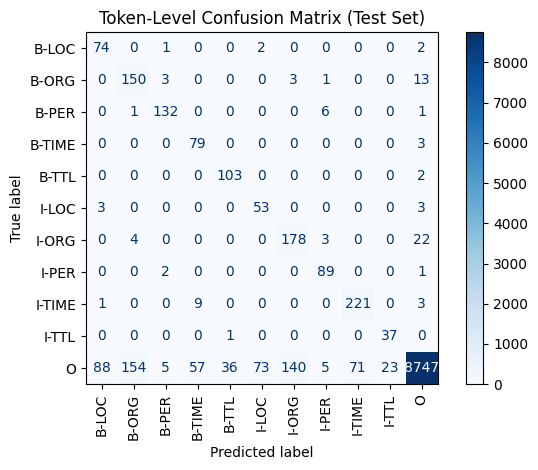

In [ ]:
plt.figure(figsize=(12, 12))
disp = ConfusionMatrixDisplay(cm, display_labels=label_list)
disp.plot(cmap="Blues", xticks_rotation=90)
plt.title("Token-Level Confusion Matrix (Test Set)")
plt.tight_layout()
plt.show()

In [ ]:
!pip install --upgrade transformers datasets evaluate seqeval


In [ ]:
!pip install imbalanced-learn
